# Daily comparison: Mumbai and Bengaluru

In this notebook, we compare the daily cycle of temperature, rainfall and humidity in
Mumbai (on the coast) and Bengaluru (on the Deccan plateau, 900 m). We use
`plot_radial_hourly`, which draws hourly data as a 24-hour clock. Midnight is at the
top and the hours go clockwise. Each ring is a month, with January at the centre, and
each cell is the mean of that hour in that month.

In [1]:
import pandas as pd

import varunayan as v

✓ CDS API configuration is already set up and valid.


## Load the data

We download hourly ERA5 for 2023 with `era5ify_point`, at the CPCB stations in Powai
(Mumbai) and RVCE-Mailasandra (Bengaluru). For hourly data at one point,
`era5ify_point` uses the CDS time-series endpoint.

In [2]:
cities = {"Mumbai": (19.1375, 72.9151), "Bengaluru": (12.9214, 77.5025)}
frames = []
for city, (lat, lon) in cities.items():
    long = v.era5ify_point(
        f"diurnal_{city.lower()}_2023",
        ["2m_temperature", "2m_dewpoint_temperature", "total_precipitation"],
        "2023-01-01",
        "2023-12-31",
        lat,
        lon,
    )
    wide = long.pivot_table(index="datetime", columns="variable", values="value")
    frames.append(
        pd.DataFrame(
            {
                "city": city,
                "time": wide.index,
                "temp_c": wide["t2m"].to_numpy(),
                "precip_mm": wide["tp"].to_numpy(),
                "rh": v.relative_humidity_from_dewpoint(
                    wide["t2m"], wide["d2m"]
                ).to_numpy(),
            }
        )
    )
hourly = pd.concat(frames, ignore_index=True)
hourly.head()

c9a89ef55d944e1a5f9246d16c704435.zip:   0%|          | 0.00/111k [00:00<?, ?B/s]

eb73a6be625d807c05ac0170d23a74dd.zip:   0%|          | 0.00/110k [00:00<?, ?B/s]

,city,time,temp_c,precip_mm,rh
0,Mumbai,2023-01-01 00:00:00,18.11596,0.0,85.178877
1,Mumbai,2023-01-01 01:00:00,17.97048,0.0,86.163307
2,Mumbai,2023-01-01 02:00:00,17.58743,0.0,86.215197
3,Mumbai,2023-01-01 03:00:00,17.11764,0.0,86.734329
4,Mumbai,2023-01-01 04:00:00,17.81838,0.0,77.447374


## Temperature

ERA5 times are in UTC, so we set `tz="Asia/Kolkata"` to draw the hours in IST.

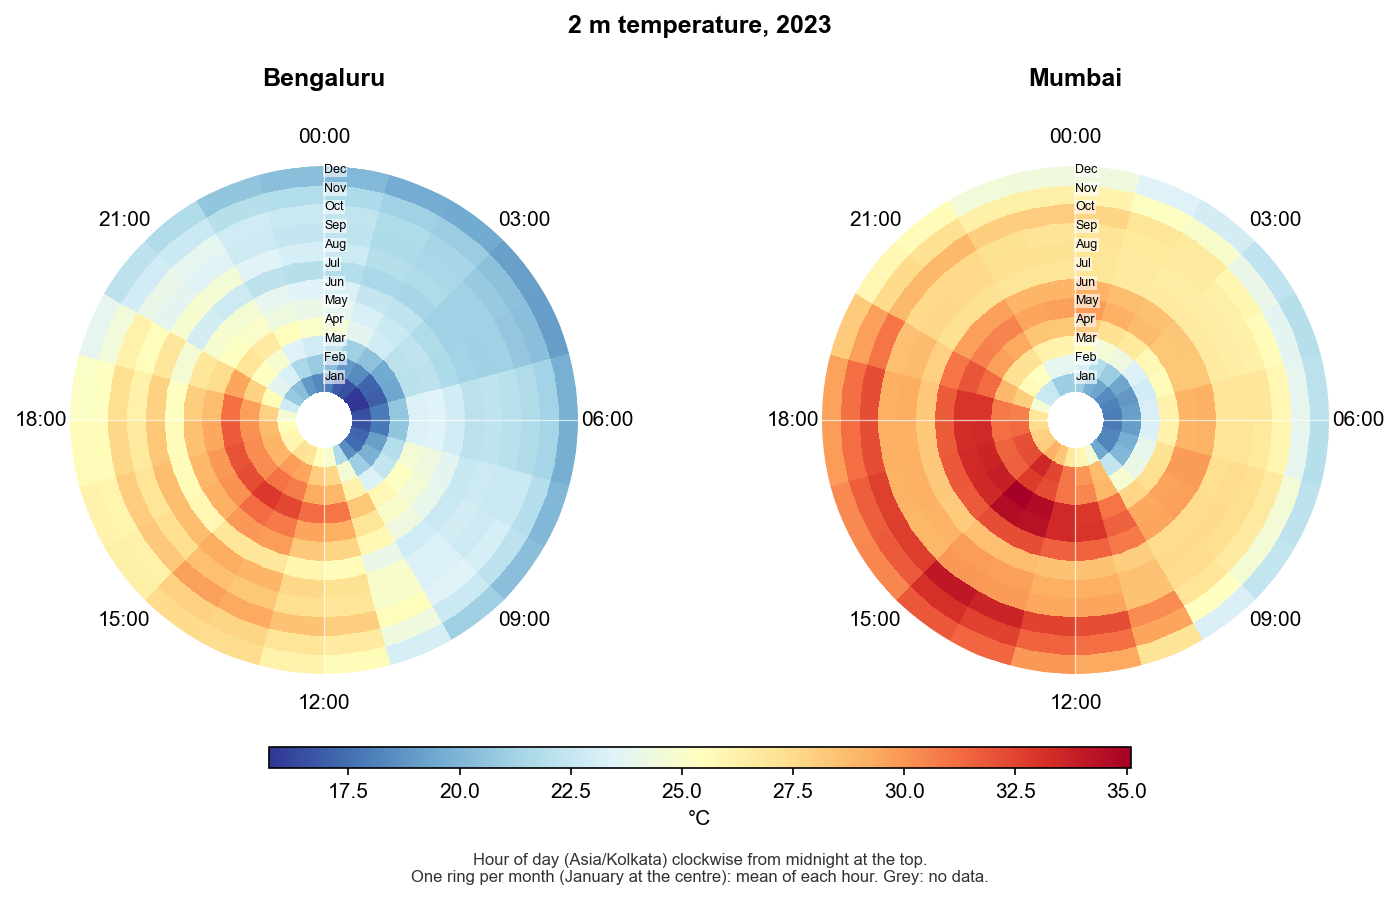

In [3]:
v.plot_radial_hourly(
    hourly,
    "temp_c",
    time="time",
    by="city",
    tz="Asia/Kolkata",
    title="2 m temperature, 2023",
    legend_title="°C",
)

Both cities are warmest at 14:00. In Bengaluru, the day is 6 to 13 °C warmer than the
night in every month. In Mumbai, the difference is 9 to 15 °C in winter and only 2 °C
in July, when the monsoon clouds stop the daily cycle.

## Rainfall

ERA5 rainfall at each time is the total of the hour before it, so we set
`accumulated=True`. In IST, each cell then covers half past one hour to half past the
next.

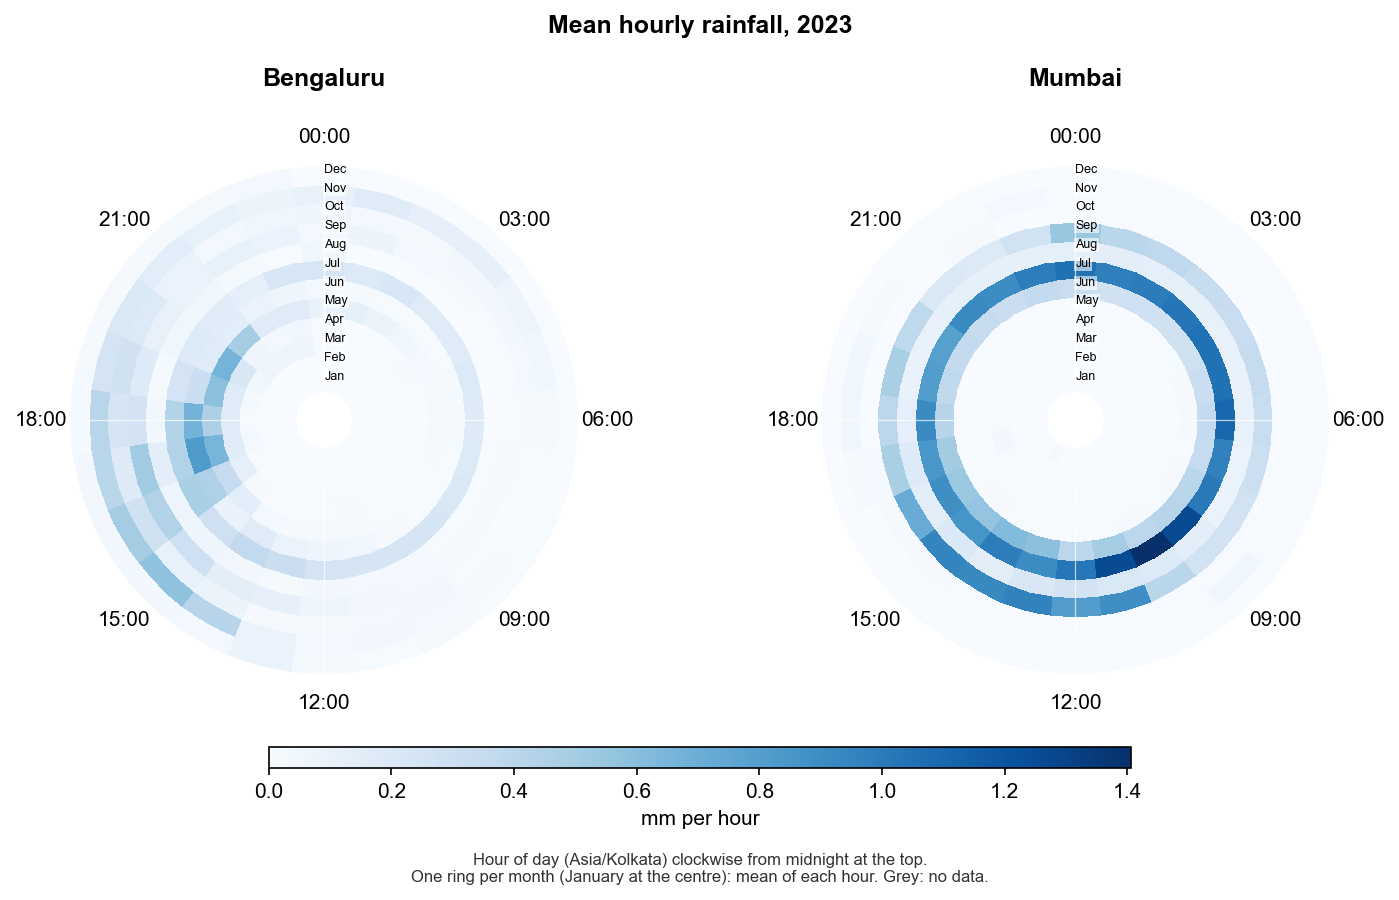

In [4]:
v.plot_radial_hourly(
    hourly,
    "precip_mm",
    time="time",
    by="city",
    tz="Asia/Kolkata",
    accumulated=True,
    cmap="Blues",
    title="Mean hourly rainfall, 2023",
    legend_title="mm per hour",
)

Mumbai gets rain from June to September, at all hours. Bengaluru gets rain in more
months, mostly in the late afternoon: 16:30 to 17:30 in the monsoon, an hour earlier in
October and November, and in the evening in April and May.

To show each day, we use `plot_radial` with `agg="sum"`.

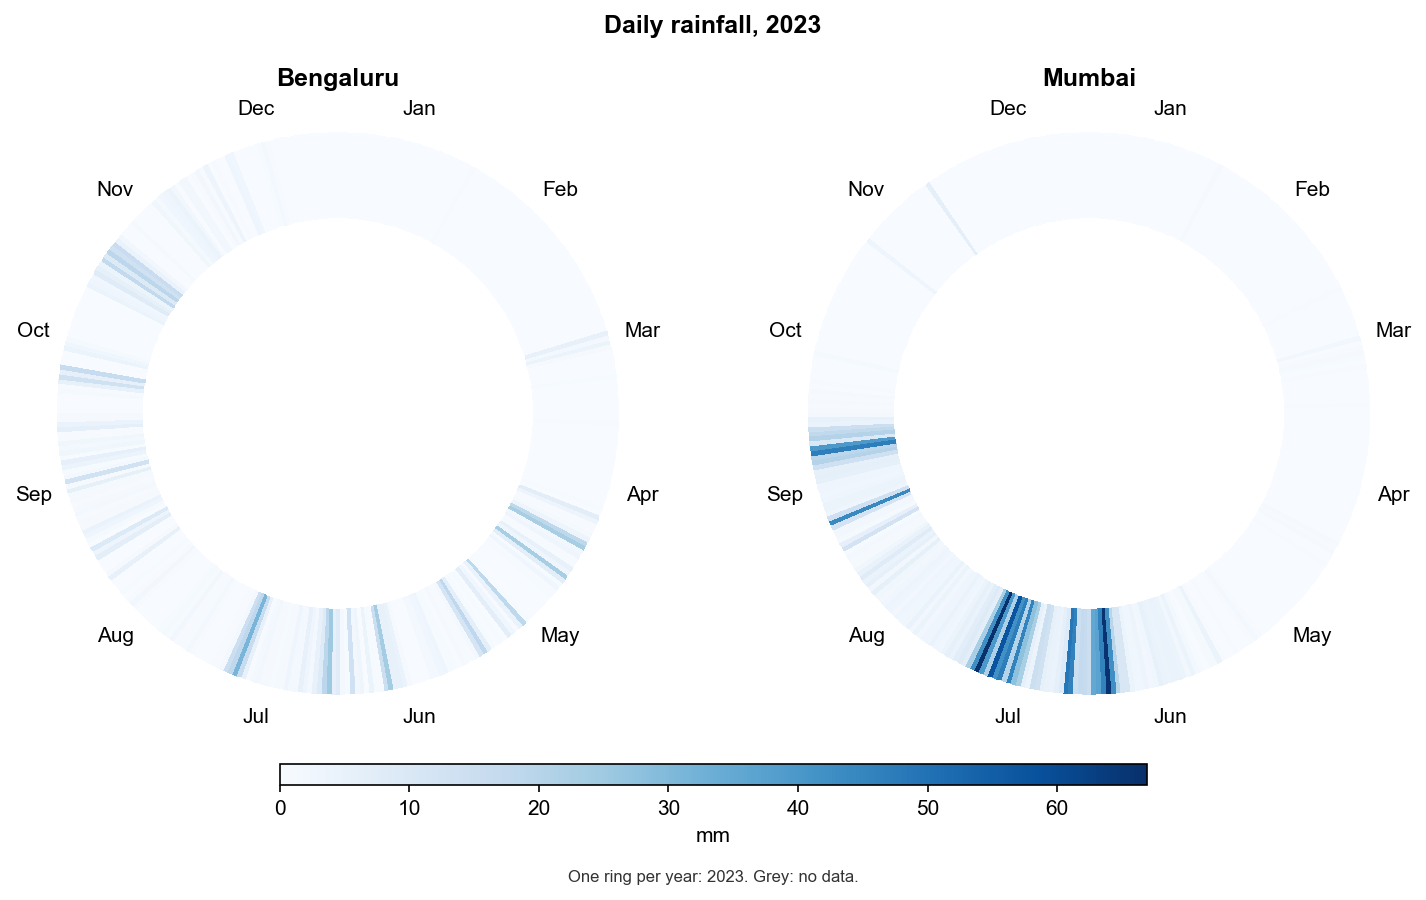

In [5]:
v.plot_radial(
    hourly,
    "precip_mm",
    time="time",
    by="city",
    agg="sum",
    cmap="Blues",
    title="Daily rainfall, 2023",
    legend_title="mm",
)

## Relative humidity

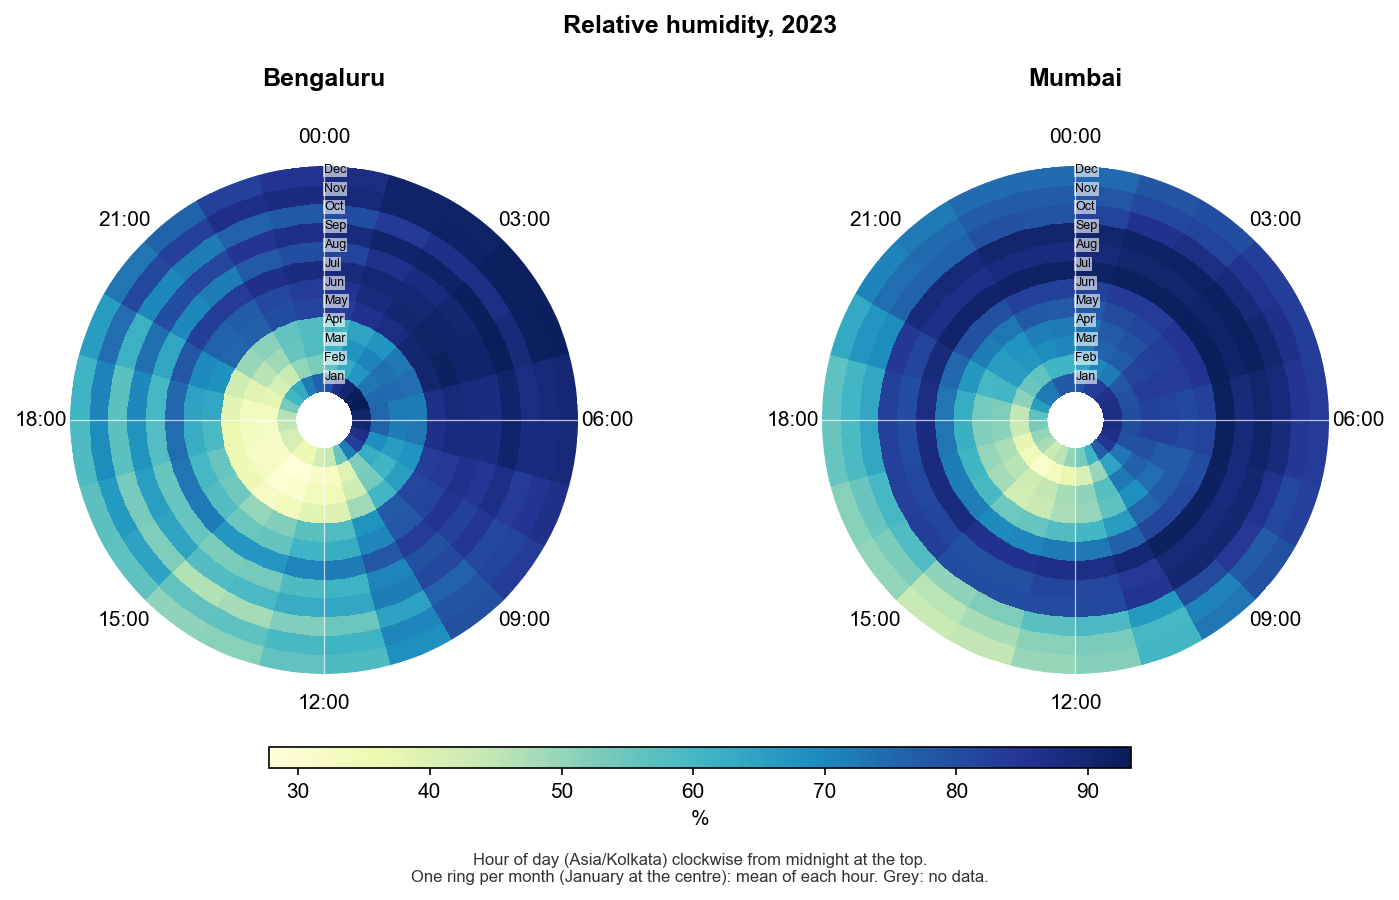

In [6]:
v.plot_radial_hourly(
    hourly,
    "rh",
    time="time",
    by="city",
    tz="Asia/Kolkata",
    cmap="YlGnBu",
    title="Relative humidity, 2023",
    legend_title="%",
)

Humidity is lowest at 14:00 in both cities. In January, it falls from 91 % at 05:00
to 35 % at 14:00 in Bengaluru. In July, Mumbai stays near 86 % all day.

Both functions take any column. Use `center=0` for anomalies and `rings="day"` for one
ring per day.